# MPS building blocks for incompressible CFD

### ENEC–TII–ENTC–KU workshop · Guided demonstration 1: Computational fluid dynamics · 24 November 2026

This notebook goes through the **building blocks** of the `tensnet` / `scripts` incompressible Navier–Stokes solver used in the QCFD project (21-rod bundle validated against Star-CCM+). Each block is described by the step of a standard CFD code (Star-CCM+, Fluent, OpenFOAM) that it replaces.

The solver keeps the stages of a standard CFD workflow. What changes is **how the data are stored**: every field, mask and operator is held in a compressed format instead of one value per cell. This splits the code into two kinds:

* **MPS subroutines** (blue). The time loop (momentum predictor, immersed-boundary penalisation, pressure-Poisson solve, velocity correction) works directly on compressed data and never expands a field to the full mesh.
* **MPS interfaces** (orange). Setup and post-processing, where standard CFD data (geometry, initial conditions, stencils, probe locations, contour plots) are converted into or out of the compressed format.

**The main message: MPS compression lowers the cost of a simulation by accepting a controlled approximation error.** It is an accuracy–cost trade-off, of the same kind as choosing a coarser mesh or a reduced-order model. The adjustable parameter is the *bond dimension* $\chi$, a "compression rank" that plays the role of a resolution budget. Each section shows both sides of the trade-off: **the saving** (how memory and work grow with mesh resolution, geometry and $\chi$) and **the price** (how much accuracy is lost when $\chi$ is capped). §9 combines them into an error budget, a required tolerance and the cheapest $\chi$ that meets it.

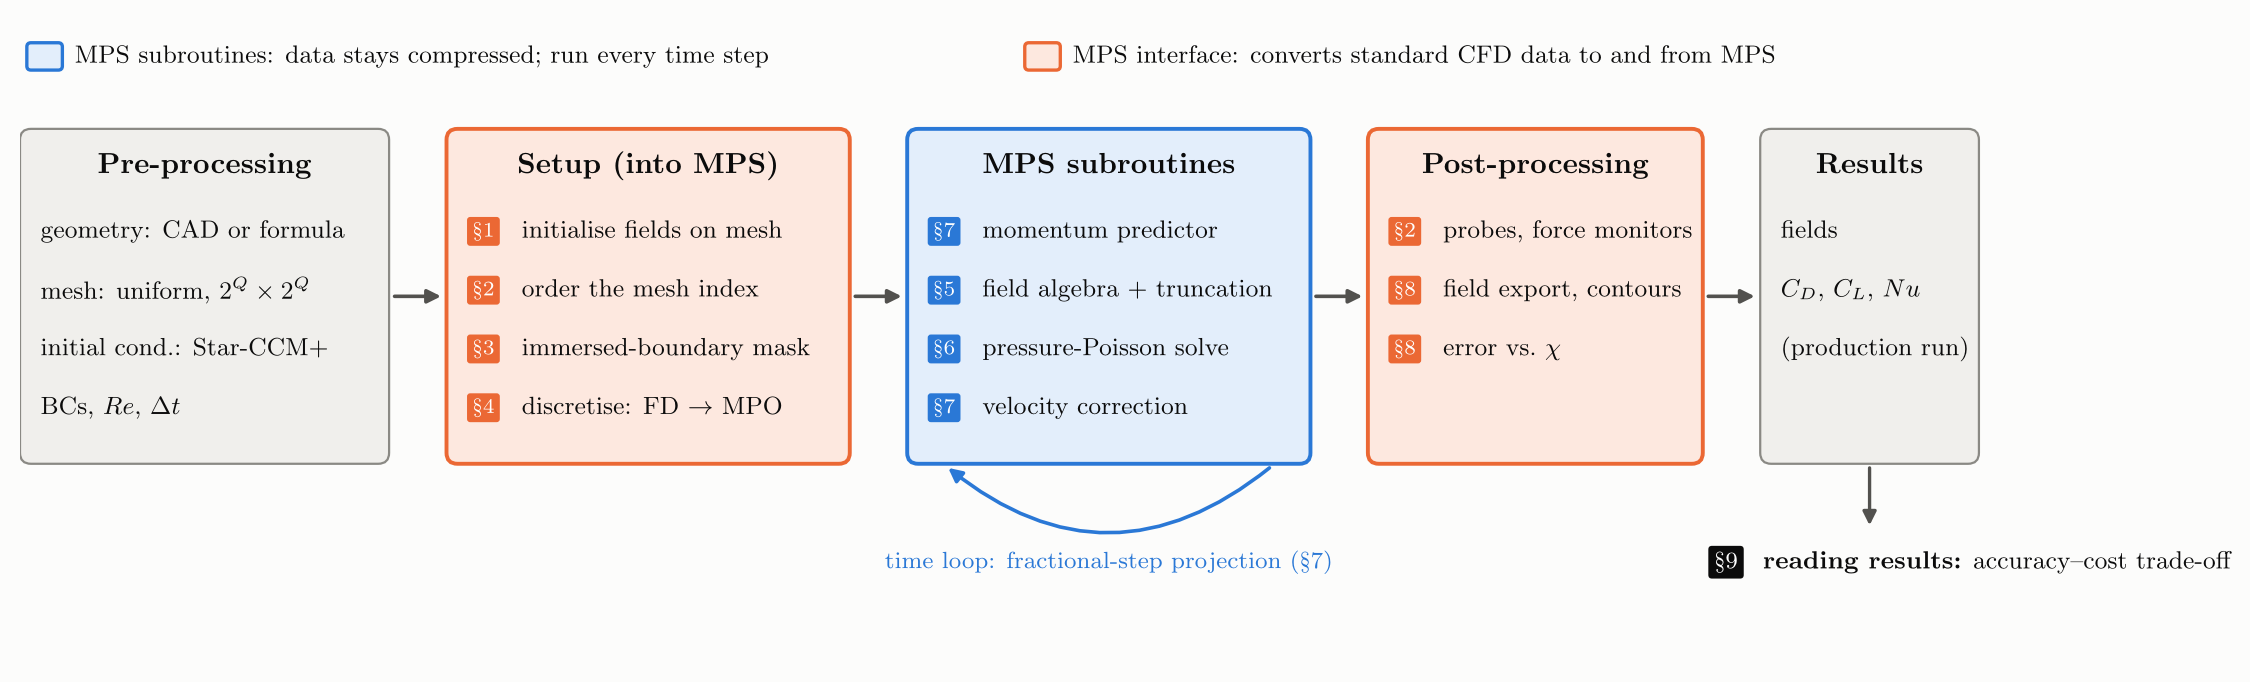

*The solver pipeline in standard CFD terms. The § tags are the notebook sections that demonstrate each stage.*

| § | Building block | Pipeline stage | Runtime (laptop CPU) |
|---|---|---|---|
| 1 | Storing a field on the mesh | setup | seconds |
| 2 | 2D meshes: ordering the mesh index; probes | setup / post-processing | seconds |
| 3 | Immersed-boundary geometry: what each geometry costs | setup | ~15 s |
| 4 | Spatial discretisation: central differences as operators | setup | seconds |
| 5 | Field algebra and truncation | MPS subroutines | seconds |
| 6 | The pressure-Poisson solve | MPS subroutines | ~15 s |
| 7 | Time steps of the projection method | MPS subroutines | ~35 s |
| 8 | Post-processing a real result: error vs. $\chi$ | post-processing | ~10 s |
| 9 | Reading results: the accuracy–cost trade-off | – | ~1 s |

**How to run.** Run from `tutorial/` in this repository (`make notebook` starts JupyterLab on it): the notebook imports `chorin_projection.py` (projection-step routines) and `bundle_simulation.py` (rod-bundle geometry) from `../scripts/`, and §8 reads `../data/archive/q11_q11_t2500_bd60_rk4.npz`. It needs `tensnet` (bundled in this repository), `torch`, `numpy` and `matplotlib` (all in the Docker image). The full production solver runs from the command line (`python bundle_simulation.py run ...`, then `python rod_forces.py ...`); see the repository README.

**To present it.** Cells tagged `reading` hold this explanatory text. `make presentation` writes `mps_cfd_building_blocks_presentation.ipynb` without them (headings, figures, equations, tables and code stay), so an audience is not distracted while the text remains here for anyone running the notebook alone.

## 0. Setup

Two `tensnet` settings are global and are set once here:

* `set_arch("sequential")`: how the mesh index is ordered inside the compressed format (§2). Fields and operators must use the same ordering.
* `set_accuracy(1e-12)`: the compression tolerance used inside arithmetic (§1.3, §5).

All derivative operators are standard **2nd-order central differences**, $(u_{j+1}-u_{j-1})/2h$ and $(u_{j+1}-2u_j+u_{j-1})/h^2$, built with `tt.diff_mpo(..., accuracy=2)` on a periodic mesh (§4).

In [1]:
import contextlib
import io
import re
import shutil
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import torch
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D

import tensnet as tt

warnings.filterwarnings("ignore")
torch.set_default_dtype(torch.float64)
tt.set_arch("sequential")  # mesh-index ordering (section 2)
tt.set_accuracy(1e-12)  # compression tolerance inside arithmetic

import os
import sys

sys.path.insert(
    0, os.path.abspath("../scripts")
)  # chorin_projection.py and bundle_simulation.py live in scripts/
import bundle_simulation as es  # rod-bundle geometry and index bookkeeping (scripts/bundle_simulation.py)
import chorin_projection as C  # projection-step routines (scripts/chorin_projection.py)

%matplotlib inline
print("tensnet", tt.__version__, "| torch", torch.__version__)

tensnet 0.1.4 | torch 2.15.0+cu132


The next cell only sets the plot style and can be skipped.

In [2]:
INK, INK2, MUTED, SURFACE, GRID = "#0b0b0b", "#52514e", "#8a8984", "#fcfcfb", "#e4e3df"
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
SEQ = LinearSegmentedColormap.from_list(
    "seq_blue", ["#f4f8fd", "#b7d3f6", "#6da7ec", "#2a78d6", "#1c5cab", "#0d366b"]
)
DIV = LinearSegmentedColormap.from_list(
    "div_bluered", ["#104281", "#3987e5", "#f0efec", "#e34948", "#8f1f1f"]
)
GEOM = LinearSegmentedColormap.from_list("geom", [INK2, SURFACE])  # solid = dark, fluid = light


def _latex_works():
    if shutil.which("latex") is None:
        return False
    try:
        with plt.rc_context({"text.usetex": True}):
            f = plt.figure()
            f.text(0.5, 0.5, r"$\chi$")
            f.canvas.draw()
            plt.close(f)
        return True
    except Exception:
        plt.close("all")
        return False


plt.rcParams.update(
    {
        "text.usetex": _latex_works(),
        "font.family": "serif",
        "font.serif": ["Computer Modern Roman"],
        "mathtext.fontset": "cm",
        "text.latex.preamble": r"\usepackage{amsmath}\usepackage{amssymb}",
        "font.size": 10,
        "axes.titlesize": 10.5,
        "axes.labelsize": 10,
        "legend.fontsize": 8.5,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "text.color": INK,
        "axes.labelcolor": INK,
        "axes.edgecolor": INK2,
        "xtick.color": INK2,
        "ytick.color": INK2,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.linewidth": 0.6,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.5,
        "axes.axisbelow": True,
        "axes.prop_cycle": plt.cycler(color=[BLUE, ORANGE, AQUA, YELLOW]),
        "lines.linewidth": 1.5,
        "lines.markersize": 4.5,
        "legend.frameon": False,
        "figure.dpi": 120,
    }
)


def field_axes(ax, title):
    ax.set_title(title)
    ax.grid(False)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_aspect("equal")
    for s in ax.spines.values():
        s.set_visible(True)
        s.set_color(GRID)

In [3]:
# Helpers: thin wrappers around tensnet calls.
def enc1d(f, L, eps=1e-12, bd=None):
    # Dense vector of length 2**L -> MPS with L cores.
    return tt.vector_to_mps(torch.as_tensor(f), 2, L, eps, bd)


def enc2d(F, Q, eps=1e-12, bd=None, interleave=True):
    # Dense 2**Q x 2**Q array -> MPS with 2Q cores (x/y bits interleaved by default).
    F = torch.as_tensor(F, dtype=torch.float64)
    v = tt.shuffle_axis(F, Q).flatten() if interleave else F.flatten()
    return tt.vector_to_mps(v, 2, 2 * Q, eps, bd)


def dec2d(m, Q):
    # MPS -> dense 2D array (only for plotting and error checks).
    return tt.unshuffle_axis(m.contract(), Q, 2)


def rel(a, b):
    # Relative L2 error ||a - b|| / ||b||.
    return float(
        torch.linalg.norm(torch.as_tensor(a) - torch.as_tensor(b))
        / torch.linalg.norm(torch.as_tensor(b))
    )


def raw_product(a, b):
    # Pointwise product core by core, WITHOUT the truncation tensnet applies in a*b.
    return tt.MPS([x * y for x, y in zip(a, b)])


def ranks(m):
    return [int(r) for r in m.ranks_list]


def mpo_ranks(A):
    return [int(n.tensor.shape[0]) for n in A.nodes][1:]


def try_project(us, vs, ops, dt, rank, opt_iter=8, max_bd=32):
    # Run chorin_projection's projection quietly. Returns (result, None), or (None, residual) if the solve failed (> 0.5).
    try:
        with contextlib.redirect_stdout(io.StringIO()):
            return C.project_divergence_free(
                us,
                vs,
                ops,
                dt,
                eps=1e-10,
                max_bd=max_bd,
                max_rank=rank,
                opt_iter=opt_iter,
                guard=0.5,
            ), None  # guard: relative residual above which the solve counts as failed
    except RuntimeError as exc:
        return None, float(re.findall(r"[0-9.]+e[+-][0-9]+", str(exc))[0])

## 1. Storing a field on the mesh

*Pipeline stage: setup: initialising a field on the mesh.*

In a standard code a field on $N$ cells is an array of $N$ numbers. Here the mesh is uniform with $N=2^L$ points per direction, and the field is stored as a chain of $L$ small arrays called a **matrix product state** (MPS).

### 1.1 Binary indexing

Write each mesh index in binary, $j = (i_1 i_2 \dots i_L)_2$: $i_1$ says which half of the domain, $i_L$ which of two neighbouring cells. The field becomes a tensor with $L$ indices of size 2, factorised as a chain of small matrices:

$$
f_{i_1 i_2\cdots i_L} \;=\; G_1[i_1]\,G_2[i_2]\cdots G_L[i_L],\qquad G_k[i_k]\in\mathbb R^{r_{k-1}\times r_k},\quad r_0=r_L=1 .
$$

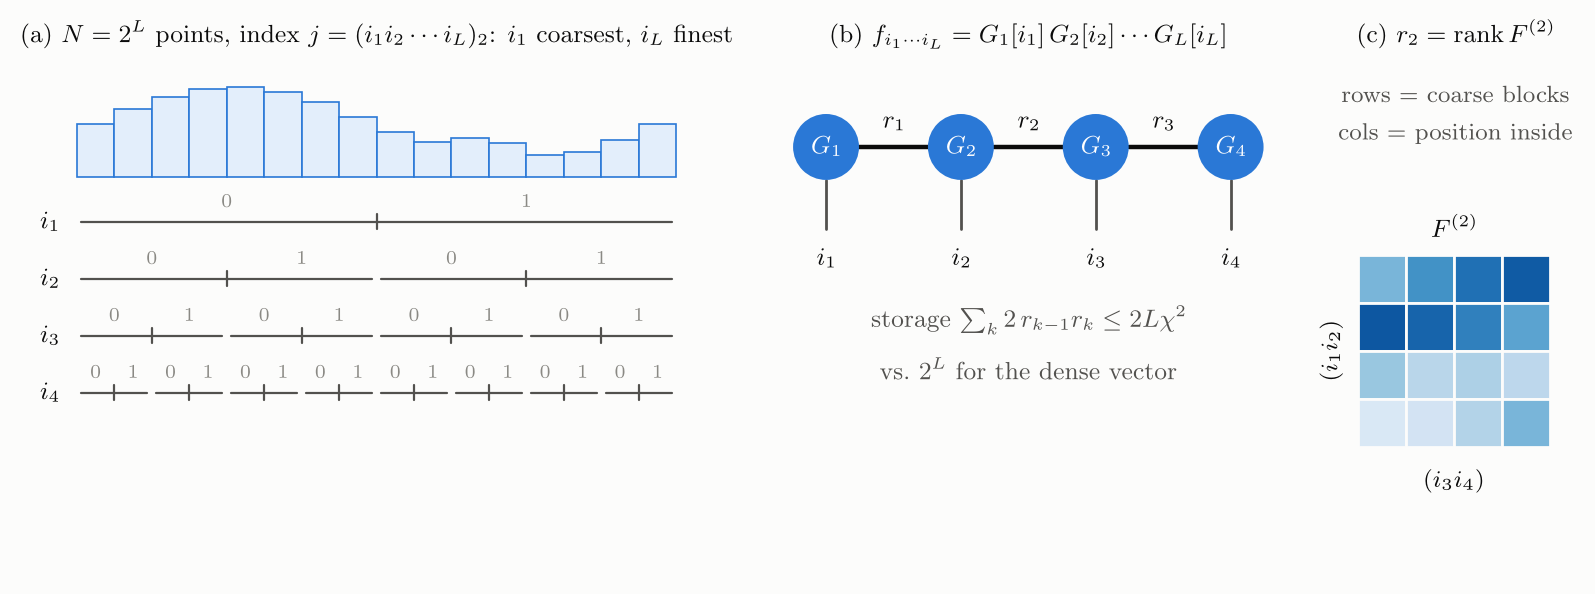

*(a) Each binary digit of the mesh index halves the previous interval, so the bits run from the coarsest to the finest scale. (b) One small core per bit, linked by bonds of size $r_k$. (c) $r_k$ is the rank of the matrix $F^{(k)}$ that puts "which coarse block" on the rows and "where inside the block" on the columns.*

The **bond dimensions** $r_k$ set the cost. Each row of $F^{(k)}$ is the field restricted to one block of $2^{L-k}$ cells, so

$$
r_k=\operatorname{rank}\big(F^{(k)}\big),\qquad F^{(k)}\in\mathbb R^{2^k\times 2^{L-k}},
$$

counts **how many genuinely different shapes the field takes inside blocks of that size**. A smooth field looks alike, up to scaling and offset, in every block, so its ranks stay small; this is the same property that makes multigrid and wavelet compression work.

### 1.2 Storage

$$
N_{\text{MPS}}=\sum_{k=1}^{L} 2\,r_{k-1}r_k\;\le\;2L\chi^2,\qquad \chi=\max_k r_k .
$$
If $\chi$ stays bounded under mesh refinement, storage grows **linearly in $L=\log_2 N$** instead of linearly in $N$: each refinement adds one core instead of doubling the array. Whether $\chi$ stays bounded depends on the field.

### 1.3 Truncation: the source of compression error

`tt.vector_to_mps` (from a dense array) and `MPS.compress` (re-compressing an MPS) build the chain by a sweep of SVDs. At each bond they discard singular values whose tail is below $\varepsilon\,\|\cdot\|$, and optionally cap the bond at $\chi_{\max}$. In this notebook **truncation** always means this SVD cut. Its total error is bounded by

$$
\frac{\|f-\tilde f\|}{\|f\|}\;\le\;\Big(\sum_{k}\varepsilon_k^2\Big)^{1/2}\le \sqrt{L-1}\;\varepsilon .
$$

A tolerance $\varepsilon$ fixes the accuracy and lets the rank adapt; a cap $\chi_{\max}$ fixes the cost and lets the error adapt. **The production solver runs on a $\chi$ cap**, so its error is the quantity to monitor.

In [4]:
# Ranks of three 1D fields as the mesh is refined from 2**6 to 2**20 points.
Ls = [6, 8, 10, 12, 14, 16, 18, 20]
fields = {
    "sin(4 pi x)  (exact rank 2)": lambda x: torch.sin(4 * np.pi * x),
    "Gaussian, width 0.05": lambda x: torch.exp(-(((x - 0.4) / 0.05) ** 2)),
    "step at x = 1/3 (discontinuous)": lambda x: (x > 1 / 3).double(),
}
print(f"{'field':36s}" + "".join(f"  L={L:<3d}" for L in Ls))
for name, f in fields.items():
    row = []
    for L in Ls:
        x = torch.linspace(0, 1, 2**L)
        row.append(int(enc1d(f(x), L, eps=1e-10).max_rank))
    print(f"{name:36s}" + "".join(f"  {r:<5d}" for r in row))

field                                 L=6    L=8    L=10   L=12   L=14   L=16   L=18   L=20 


sin(4 pi x)  (exact rank 2)           2      2      2      2      2      2      2      2    


Gaussian, width 0.05                  4      8      9      9      9      9      9      9    


step at x = 1/3 (discontinuous)       2      2      2      2      2      2      2      2    


At $10^6$ points each of these fields needs only a handful of numbers per bond. A single jump costs rank 2: each coarse block is "all 0", "all 1", or the one block that contains the jump. **Discontinuities are cheap in 1D; in 2D they are not (§3)**, because a curved interface cuts many blocks in many different ways.

Capping $\chi$ on one test field shows the trade-off directly:

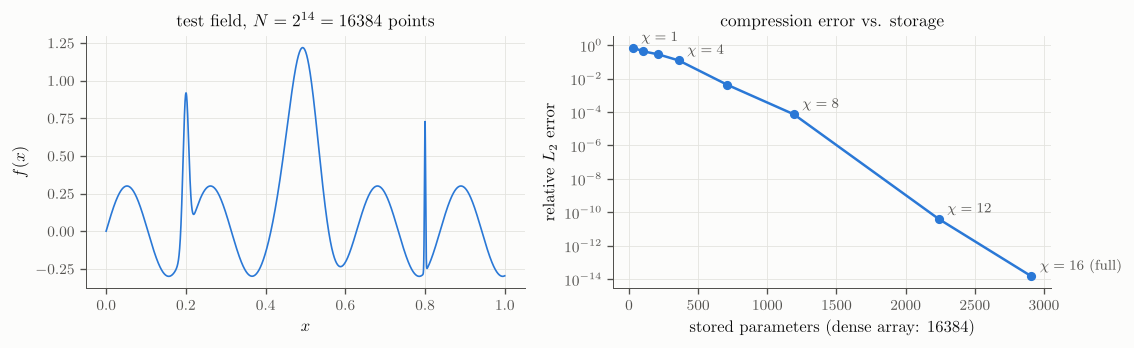

chi = 8: error 7.3e-05 with 1192 parameters (14x fewer than the dense array)


In [5]:
L = 14
x = torch.linspace(0, 1, 2**L)
f = sum(
    torch.exp(-(((x - c) / w) ** 2)) for c, w in [(0.2, 0.01), (0.5, 0.05), (0.8, 0.002)]
) + 0.3 * torch.sin(30 * x)
full = enc1d(f, L, eps=1e-14)
chi_full = int(full.max_rank)
chis = [c for c in [1, 2, 3, 4, 6, 8, 12, 16, 24] if c < chi_full] + [chi_full]
errs, params = [], []
for chi in chis:
    c = full.compress(accuracy=1e-14, max_bd=chi)
    errs.append(rel(c.contract(), f))
    params.append(c.num_params)

fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.0))
ax[0].plot(x, f, color=BLUE, lw=1.0)
ax[0].set_xlabel(r"$x$")
ax[0].set_ylabel(r"$f(x)$")
ax[0].set_title(rf"test field, $N=2^{{{L}}}={2**L}$ points")
ax[1].semilogy(params, errs, "o-", color=BLUE)
for chi, p, e in zip(chis, params, errs):
    if chi in (1, 4, 8, 12) or chi == chi_full:
        lab = rf"$\chi={chi}$" + (" (full)" if chi == chi_full else "")
        ax[1].annotate(
            lab, (p, e), textcoords="offset points", xytext=(5, 4), fontsize=8.5, color=INK2
        )
ax[1].set_xlabel(rf"stored parameters (dense array: ${2**L}$)")
ax[1].set_ylabel(r"relative $L_2$ error")
ax[1].set_title(r"compression error vs. storage")
fig.tight_layout()
plt.show()
i8 = chis.index(8)
print(
    f"chi = 8: error {errs[i8]:.1e} with {params[i8]} parameters ({2**L / params[i8]:.0f}x fewer than the dense array)"
)

The error falls exponentially with $\chi$: at $\chi=8$ the field is stored to about $10^{-4}$ with an order of magnitude fewer numbers than the dense array.

## 2. Two-dimensional meshes: ordering the mesh index

*Pipeline stage: setup (2D fields) and post-processing (probes).*

A $2^Q\times2^Q$ mesh has $2Q$ index bits, $Q$ for $x$ and $Q$ for $y$. `tt.shuffle_axis` **interleaves** them, $x_1y_1x_2y_2\cdots x_Qy_Q$, most significant first. Each pair of cores then splits a square cell into its four quadrants, like a quadtree, so every bond separates **scales**, not directions. The alternative, $x_1\cdots x_Q\,y_1\cdots y_Q$, puts a bond between "all of $x$" and "all of $y$"; its rank is the matrix rank of the field, which for a curved obstacle grows with $2^Q$.

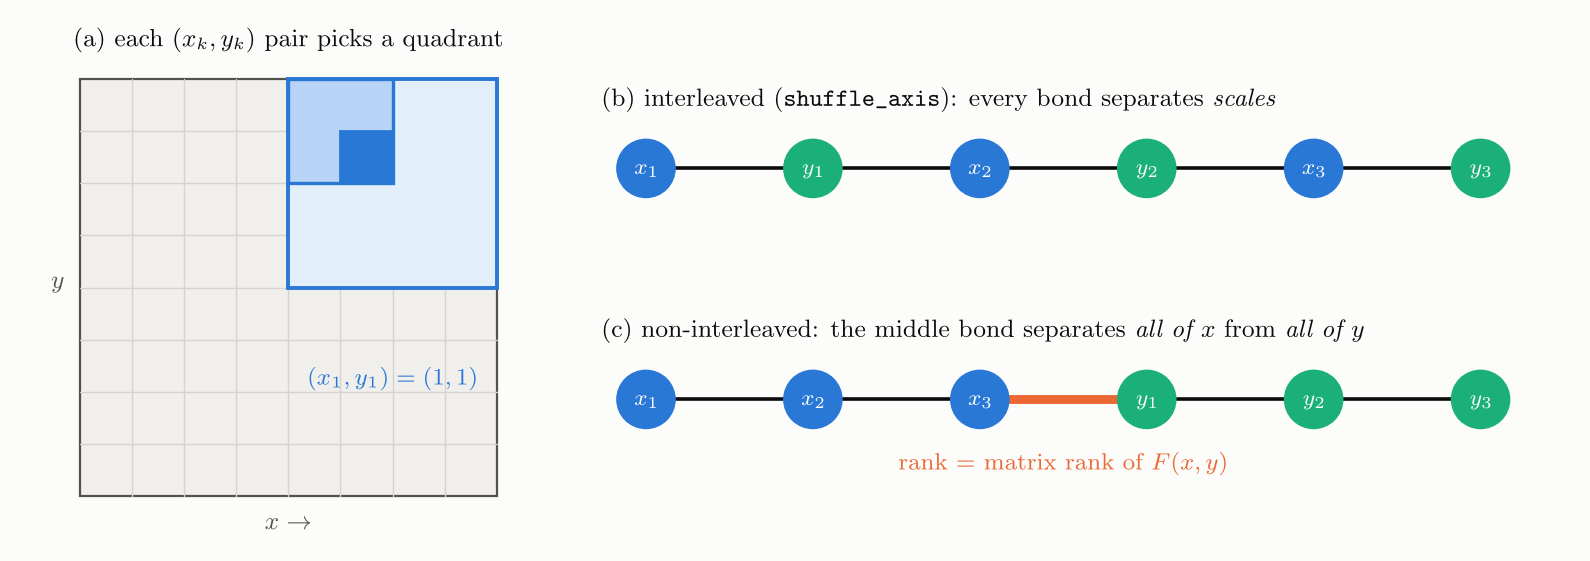

*(a) Each pair $(x_k,y_k)$ selects a quadrant of the previous cell. (b) Interleaved ordering, used by the solver. (c) Non-interleaved ordering: its middle bond carries the full matrix rank of the field.*

**Probes.** `bundle_simulation.shuffled_index` converts mesh coordinates $(i_x,i_y)$ to the interleaved index, and `MPS.query` evaluates the field at those points **without expanding it to the full mesh**, at $O(L\chi^2)$ per point. Force monitors read their probe points from the compressed velocity field this way.

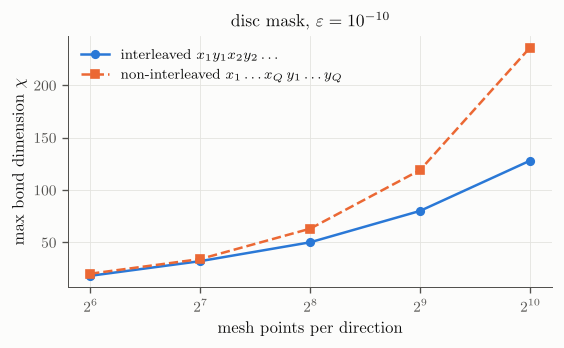

probe values from MPS : [1. 0. 1.]
same points, dense    : [1. 0. 1.]


In [6]:
def disc(Q, r0=0.3):
    # Fluid mask around an off-centre disc, built with bundle_simulation.cylinder (the project's construction, section 3).
    x = torch.linspace(-1, 1, 2**Q)
    X, Y = torch.meshgrid(x, x, indexing="ij")
    return 1.0 - es.cylinder(X, Y, 0.1, -0.05, r0)


Qs2 = [6, 7, 8, 9, 10]
inter, seq = [], []
for Q in Qs2:
    F = disc(Q)
    inter.append(int(enc2d(F, Q, 1e-10).max_rank))
    seq.append(int(enc2d(F, Q, 1e-10, interleave=False).max_rank))
fig, ax = plt.subplots(figsize=(4.8, 3.0))
ax.plot(Qs2, inter, "o-", color=BLUE, label=r"interleaved $x_1y_1x_2y_2\ldots$")
ax.plot(Qs2, seq, "s--", color=ORANGE, label=r"non-interleaved $x_1\ldots x_Q\,y_1\ldots y_Q$")
ax.set_xticks(Qs2)
ax.set_xticklabels([rf"$2^{{{q}}}$" for q in Qs2])
ax.set_xlabel(r"mesh points per direction")
ax.set_ylabel(r"max bond dimension $\chi$")
ax.set_title(r"disc mask, $\varepsilon=10^{-10}$")
ax.legend()
fig.tight_layout()
plt.show()

# Probes: read single mesh points straight from the MPS
Q = 8
F = disc(Q)
m = enc2d(F, Q)
ix, iy = np.array([10, 128, 200]), np.array([40, 128, 77])
print(
    "probe values from MPS :",
    np.round(m.query(es.shuffled_index(ix, iy, Q).tolist()).numpy(), 6) + 0.0,
)
print("same points, dense    :", np.round(F[ix, iy].numpy(), 6))

Interleaving roughly halves $\chi$ at $1024^2$, but does not stop it growing. The solver uses the interleaved ordering throughout.

## 3. Immersed-boundary geometry: what each geometry costs

*Pipeline stage: setup: the equivalent of meshing around the solid.*

The solver has no body-fitted mesh. Solids are represented on the uniform Cartesian mesh by a **mask** $m(\mathbf x)$, 1 in the fluid and 0 inside solids, which multiplies the predicted velocity, $\mathbf u^* \leftarrow m \odot \mathbf u^*$, before the pressure projection. This is **volume penalisation** (a Brinkman-type immersed-boundary method) with penalty parameter $\Delta t$; no-slip holds to $O(\Delta t)$.

The mask is a **non-MPS input** (a shape from CAD or a formula) that must be converted to an MPS. Its rank also sets a floor under the rank of every field it multiplies, so the geometry partly sets the cost of the whole run.

**How the mask is built.** The project's scripts (`bundle_simulation.cylinder`) use an indicator that is exactly 1 inside the solid and decays exponentially outside,

$$
\text{solid}(\mathbf x) = \exp\!\big(-\alpha\,(v + |v|)\big),\qquad v = |\mathbf x-\mathbf x_c|^2 - r^2,\qquad m = 1-\text{solid}.
$$

$v+|v|$ is zero inside, so the indicator is flat there. With $\alpha = \alpha_\mathrm{ref}\,r_\mathrm{ref}/r$ ($\alpha_\mathrm{ref}=10^3$, $r_\mathrm{ref}=0.1$) the interface has a **fixed physical width** of about $1/(4\alpha_\mathrm{ref} r_\mathrm{ref}) = 0.0025$ domain units. On a coarse mesh it is thinner than a cell and the mask is a sharp 0/1 staircase; once a few cells span it, refinement resolves the same interface instead of sharpening it. The other shapes below use the same construction with $v$ replaced by a level-set function of the shape.

Two things set the mask rank:

* **Resolution of the interface.** While it is under-resolved, every boundary block holds a different staircase pattern, so the rank grows with refinement.
* **Alignment with the mesh.** An axis-aligned square at dyadic positions is almost free at any resolution; curves and slanted edges are not.

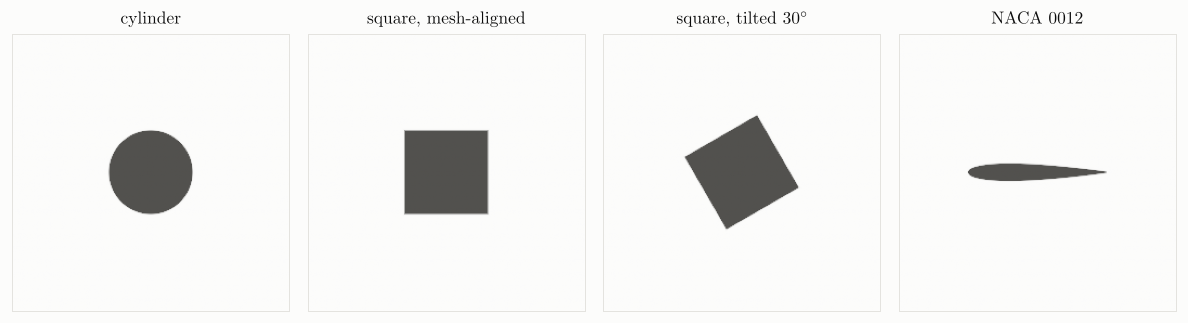

In [7]:
def grid2d(Q, a=-1.0, b=1.0):
    x = torch.linspace(a, b, 2**Q)
    return torch.meshgrid(x, x, indexing="ij")


# Level-set functions: negative inside the solid, positive in the fluid, zero on the surface.
def g_square(X, Y):
    return torch.maximum(X.abs(), Y.abs()) - 0.3  # axis-aligned box


def g_tilted(X, Y):  # same box rotated 30 degrees
    c, s = np.cos(np.pi / 6), np.sin(np.pi / 6)
    return torch.maximum((c * X + s * Y).abs(), (-s * X + c * Y).abs()) - 0.3


def g_naca(X, Y, t=0.12):  # NACA 0012, chord 1
    xc = (X + 0.5).clamp(0, 1)
    yt = (
        5
        * t
        * (0.2969 * torch.sqrt(xc) - 0.126 * xc - 0.3516 * xc**2 + 0.2843 * xc**3 - 0.1015 * xc**4)
    )
    inside = (X + 0.5 >= 0) & (X + 0.5 <= 1)
    return torch.where(inside, Y.abs() - yt, torch.full_like(X, 1.0))


ALPHA_D = (
    2 * es.ALPHA * es.R_REF
)  # per unit distance: same interface width as bundle_simulation.cylinder


def solid_from_levelset(g):
    # The bundle_simulation construction with a level set g in place of r^2 - R^2: 1 inside, exponential decay outside.
    return lambda X, Y: torch.exp(-ALPHA_D * (g(X, Y) + g(X, Y).abs()))


GEOMS = {
    "cylinder": lambda X, Y: es.cylinder(X, Y, 0.0, 0.0, 0.3),  # the project's own function
    "square, mesh-aligned": solid_from_levelset(g_square),
    "square, tilted 30 deg": solid_from_levelset(g_tilted),
    "NACA 0012": solid_from_levelset(g_naca),
}
GCOL = dict(zip(GEOMS, [BLUE, ORANGE, AQUA, YELLOW]))
TEXNAME = {
    "cylinder": r"cylinder",
    "square, mesh-aligned": r"square, mesh-aligned",
    "square, tilted 30 deg": r"square, tilted $30^\circ$",
    "NACA 0012": r"NACA 0012",
}


def mask(solid, Q):
    X, Y = grid2d(Q)
    return 1.0 - solid(X, Y)  # fluid mask: 1 in the fluid, 0 in the solid


fig, ax = plt.subplots(1, 4, figsize=(10, 2.7))
for a, (name, solid) in zip(ax, GEOMS.items()):
    a.imshow(mask(solid, 8).T, origin="lower", cmap=GEOM, extent=[-1, 1, -1, 1])
    field_axes(a, TEXNAME[name])
fig.tight_layout()
plt.show()

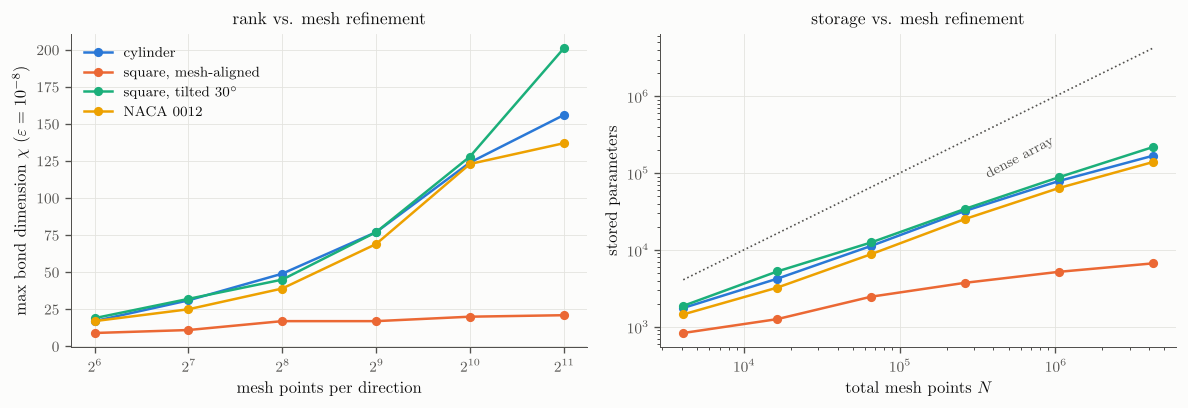

chi per refinement level:
  cylinder               [17, 31, 49, 77, 124, 156]
  square, mesh-aligned   [9, 11, 17, 17, 20, 21]
  square, tilted 30 deg  [19, 32, 45, 77, 128, 201]
  NACA 0012              [17, 25, 39, 69, 123, 137]


In [8]:
Qs = [6, 7, 8, 9, 10, 11]
res = {}
for name, solid in GEOMS.items():
    res[name] = [enc2d(mask(solid, Q), Q, eps=1e-8) for Q in Qs]

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for name in GEOMS:
    ax[0].plot(
        Qs, [int(m.max_rank) for m in res[name]], "o-", color=GCOL[name], label=TEXNAME[name]
    )
    ax[1].loglog([4.0**Q for Q in Qs], [m.num_params for m in res[name]], "o-", color=GCOL[name])
ax[1].loglog([4.0**Q for Q in Qs], [4.0**Q for Q in Qs], ":", color=INK2, lw=1.0)
ax[1].text(4.0**9.2, 4.0**9.2 * 0.25, r"dense array", fontsize=8.5, color=INK2, rotation=28)
ax[0].set_xticks(Qs)
ax[0].set_xticklabels([rf"$2^{{{q}}}$" for q in Qs])
ax[0].set_xlabel(r"mesh points per direction")
ax[0].set_ylabel(r"max bond dimension $\chi$ ($\varepsilon=10^{-8}$)")
ax[0].set_title(r"rank vs. mesh refinement")
ax[0].legend()
ax[1].set_xlabel(r"total mesh points $N$")
ax[1].set_ylabel(r"stored parameters")
ax[1].set_title(r"storage vs. mesh refinement")
fig.tight_layout()
plt.show()
print("chi per refinement level:")
for name in GEOMS:
    print(f"  {name:22s}", [int(m.max_rank) for m in res[name]])

* **Curved and slanted shapes grow in rank under refinement while the interface is under-resolved**, by roughly 1.5–1.7× per level. At $2^{11}$, where about 2.5 cells span the interface, the cylinder and the NACA profile start to level off; the tilted square does not yet, as its slanted edges need a finer mesh. Storage still grows far more slowly than the dense array.
* **The mesh-aligned square is the cheapest geometry at every resolution; at the finest mesh its tilted copy is the most expensive** (χ ≈ 200 vs. ≈ 20). Alignment with the dyadic mesh and resolution of the interface set the cost.

At fixed resolution, capping $\chi$ gives the compression error of each mask:

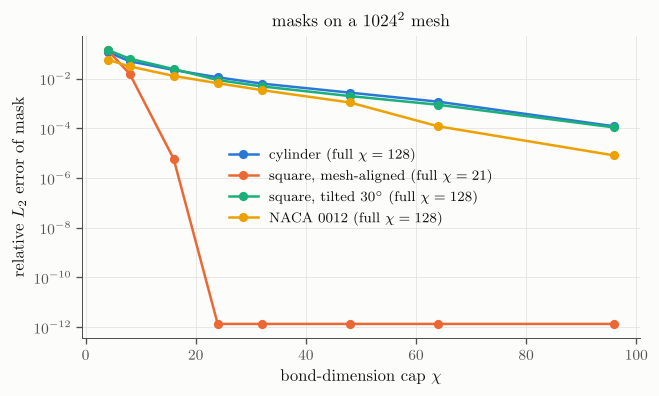

In [9]:
Q = 10
chis_m = [4, 8, 16, 24, 32, 48, 64, 96]
fig, ax = plt.subplots(figsize=(5.6, 3.4))
for name, solid in GEOMS.items():
    F = mask(solid, Q)
    full = enc2d(F, Q, eps=1e-12)
    e = [rel(dec2d(full.compress(accuracy=1e-14, max_bd=c), Q), F) for c in chis_m]
    ax.semilogy(
        chis_m,
        e,
        "o-",
        color=GCOL[name],
        label=TEXNAME[name] + rf" (full $\chi={int(full.max_rank)}$)",
    )
ax.set_xlabel(r"bond-dimension cap $\chi$")
ax.set_ylabel(r"relative $L_2$ error of mask")
ax.set_title(rf"masks on a ${2**Q}^2$ mesh")
ax.legend()
fig.tight_layout()
plt.show()

The mesh-aligned square is exact from $\chi=24$; the curved and slanted shapes need $\chi\approx64$ for a mask error of $10^{-3}$ and $\chi\approx100$ for $10^{-4}$ at $1024^2$. Their "full" rank of 128 is the largest a bond near the fine end of a 20-core chain can have: at the finest scales an under-resolved interface does not compress at all.

### 3.1 The 21-rod bundle: building the geometry directly in compressed form

The ENEC validation case is a 5×5 lattice of rods with the four corners removed (21 rods, pitch $P=2D$). `bundle_simulation.build_mask` never forms the full mask array. It builds two small MPSs, a coarse $2^p\times2^p$ **lattice** of rod positions and a fine $2^{L_f}\times2^{L_f}$ block holding **one rod**, and **concatenates their cores**. Concatenation is a Kronecker product: coarse bits select a lattice cell, fine bits a point inside it, which copies the rod into every flagged cell. The junction bond of the solid indicator has dimension 1, and forming $m = 1-\text{solid}$ adds one more, so

$$
\chi(\text{bundle}) \;\le\; \max\big(\chi(\text{lattice}),\,\chi(\text{rod})\big)+1 .
$$

Mesh refinement means raising $L_f$ at fixed $p$; rod pitch and diameter stay fixed in physical units. **Exploiting the periodicity of the lattice makes the geometry input cheap**, which carries over to reactor internals made of repeated assemblies.

 mesh points    chi   parameters   dense values   time
    256^2        8         532          65536   0.02s
    512^2       13         984         262144   0.02s
   1024^2       21        2250        1048576   0.02s
   2048^2       32        5676        4194304   0.02s
   4096^2       60       16026       16777216   0.04s
   8192^2       81       38282       67108864   0.08s


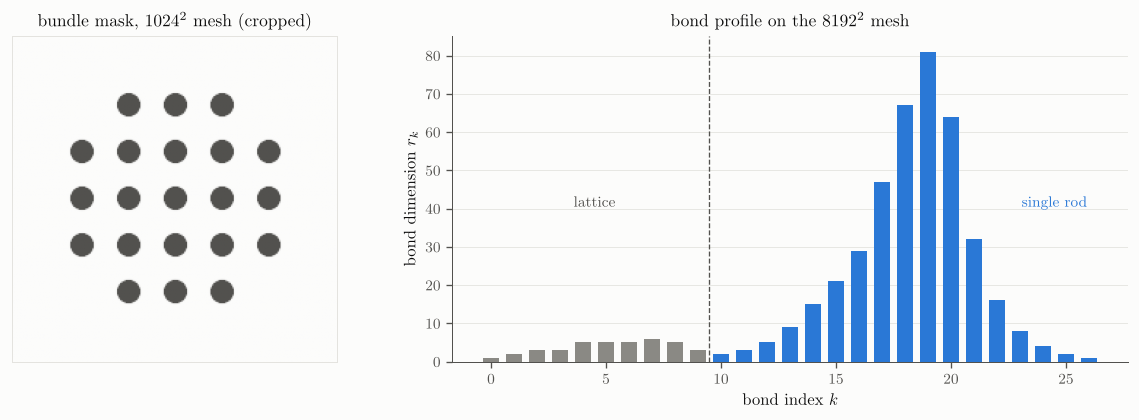

In [10]:
print(" mesh points    chi   parameters   dense values   time")
bundle = {}
for Lf in [3, 4, 5, 6, 7, 8]:
    t0 = time.time()
    m = es.build_mask(5, Lf, d_over_pitch=0.5, accuracy=1e-10)
    dt_ = time.time() - t0
    bundle[5 + Lf] = m
    print(
        f"  {2 ** (5 + Lf):5d}^2     {int(m.max_rank):4d}  {m.num_params:10d}   {4 ** (5 + Lf):12d}   {dt_:.2f}s"
    )

Q = 10
M = dec2d(bundle[Q], Q).numpy()
bx, by = np.where(M < 0.5)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw={"width_ratios": [1, 1.6]})
ax[0].imshow(
    M[bx.min() - 40 : bx.max() + 40, by.min() - 40 : by.max() + 40].T, origin="lower", cmap=GEOM
)
field_axes(ax[0], rf"bundle mask, ${2**Q}^2$ mesh (cropped)")
r13 = ranks(bundle[13])
ax[1].bar(range(len(r13)), r13, width=0.7, color=[MUTED] * 10 + [BLUE] * (len(r13) - 10))
ax[1].axvline(9.5, color=INK2, lw=0.8, ls="--")
ax[1].text(4.5, max(r13) * 0.5, r"lattice", ha="center", fontsize=9, color=INK2)
ax[1].text(24.5, max(r13) * 0.5, r"single rod", ha="center", fontsize=9, color=BLUE)
ax[1].set_xlabel(r"bond index $k$")
ax[1].set_ylabel(r"bond dimension $r_k$")
ax[1].grid(axis="x", visible=False)
ax[1].set_title(r"bond profile on the $8192^2$ mesh")
fig.tight_layout()
plt.show()

The $8192^2$ mask (67 million mesh points) takes a fraction of a second and a few tens of thousands of parameters, and its rank sits entirely in the rod block. The rank still grows with refinement, as in §3; the block construction is what keeps it cheap.

## 4. Spatial discretisation: central differences as operators

*Pipeline stage: setup: building the discretised operators, as a standard code assembles its matrices once.*

A finite-difference operator on $2^L$ points is a banded matrix. In compressed form it becomes a **matrix product operator** (MPO): a chain like the MPS, with an input and an output index on each core. Its bond dimension depends on the stencil and **not on $L$**, because a shift by $\pm1$ in binary is a carry that moves along the chain and needs only a few states. The notebook uses the standard 2nd-order central differences

$$
\partial_x u\big|_j\approx\frac{u_{j+1}-u_{j-1}}{2h},\qquad
\partial_x^2 u\big|_j\approx\frac{u_{j+1}-2u_j+u_{j-1}}{h^2},\qquad\text{discretisation error } O(h^2),
$$

built with one call:

```python
A = tt.diff_mpo(order, nofq, axis, bounds=(a, b), grid="periodic", accuracy=2)
```

* `order` is the derivative order (1 or 2); `accuracy=2` selects the 3-point stencils above.
* `grid="periodic"` places $n=2^L$ nodes on $[a,b)$ with spacing $h=(b-a)/n$; the spacing is included in the operator.
* On a 2D mesh (`nofq=[Q, Q]`) the 1D operator acts on the $x$ or $y$ bits of the interleaved chain (`axis=0` or `1`).

Applying an MPO of bond dimension $r_A$ to an MPS of bond dimension $\chi$ gives bond dimension up to $r_A\chi$ before truncation (§5).

max MPO bond dimension of d/dx for L = [5, 6, 8, 10, 12, 14, 16, 18, 20] -> [3, 3, 3, 3, 3, 3, 3, 3, 3]


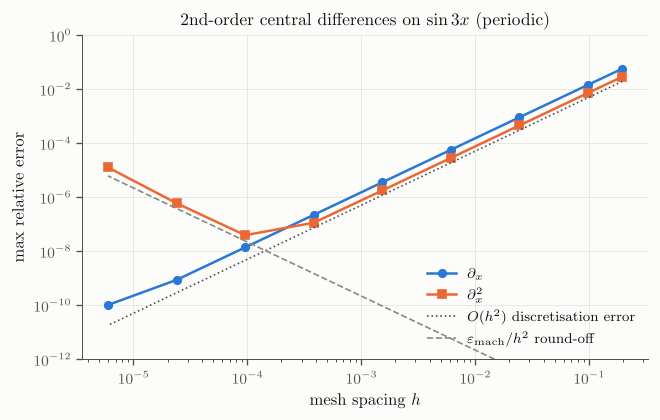

In [11]:
# Mesh-convergence study on a periodic 1D mesh: sin(3x) on [0, 2 pi).
Ls5 = [5, 6, 8, 10, 12, 14, 16, 18, 20]
e1s, e2s, rk = [], [], []
for L in Ls5:
    kw = dict(bounds=(0.0, 2 * np.pi), grid="periodic", accuracy=2)
    x = tt.grid_points(L, (0.0, 2 * np.pi), "periodic")
    f = enc1d(torch.sin(3 * x), L)
    D1, D2 = tt.diff_mpo(1, L, **kw), tt.diff_mpo(2, L, **kw)
    e1s.append(float((D1.apply(f).contract() - 3 * torch.cos(3 * x)).abs().max() / 3))
    e2s.append(float((D2.apply(f).contract() + 9 * torch.sin(3 * x)).abs().max() / 9))
    rk.append(max(mpo_ranks(D1)))
h = 2 * np.pi / 2.0 ** np.array(Ls5)
print("max MPO bond dimension of d/dx for L =", Ls5, "->", rk)

fig, ax = plt.subplots(figsize=(5.6, 3.6))
ax.loglog(h, e1s, "o-", color=BLUE, label=r"$\partial_x$")
ax.loglog(h, e2s, "s-", color=ORANGE, label=r"$\partial_x^2$")
ax.loglog(h, 0.5 * h**2, ":", color=INK2, lw=1.0, label=r"$O(h^2)$ discretisation error")
ax.loglog(
    h, 2.2e-16 / h**2, "--", color=MUTED, lw=1.0, label=r"$\varepsilon_\mathrm{mach}/h^2$ round-off"
)
ax.set_xlabel(r"mesh spacing $h$")
ax.set_ylabel(r"max relative error")
ax.set_ylim(1e-12, 1)
ax.set_title(r"2nd-order central differences on $\sin 3x$ (periodic)")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

* **The operator's bond dimension is 3 for every mesh size**, so it costs almost nothing to store even on $2^{20}$ points.
* **2nd-order convergence, then an error floor** at $\varepsilon_\mathrm{mach}/h^2$ for the second derivative: round-off amplified by $h^{-2}$, as in any code. A looser truncation tolerance $\varepsilon$ raises this floor to roughly $\varepsilon/h^2$. An MPS can hold $2^{30}$ points, but differentiating there is limited by conditioning and truncation, not by storage, which is why wall gradients (pressure, shear stress, heat flux) are the hardest quantities for the compressed solver.

### 4.1 The operator set used in §5–§7

The following sections use a **periodic box containing one cylinder**: a unit cell of an infinite square array of cylinders, the simplest relative of the rod bundle. The pressure-Poisson operator is **composed from the same first-derivative operators** as the divergence and gradient, $\Delta_h=D_x D_x + D_y D_y$, so that $\nabla\!\cdot\nabla\phi = \Delta_h\phi$ holds exactly in discrete form and an exact Poisson solve would remove the divergence to round-off. (A compact $\partial_x^2+\partial_y^2$ agrees with it only to $O(h^2)$.) The class below collects these operators for the projection routines in `chorin_projection.py`.

In [12]:
class CentralOps:
    # 2nd-order central-difference operators on a periodic [0,1)^2 mesh with 2**Q points per direction.
    def __init__(self, Q, bounds=(0.0, 1.0)):
        kw = dict(bounds=bounds, grid="periodic", accuracy=2)
        self.Q, self.dx, self.hold = Q, float(tt.grid_spacing(Q, bounds, "periodic")), None
        self.held_projection, self.pin, self.outflow = (
            False,
            None,
            None,
        )  # chorin_projection.py interface: no walls here
        self.Dx = self.Gx = tt.diff_mpo(
            1, [Q, Q], 0, **kw
        )  # velocity and pressure gradients share stencils
        self.Dy = self.Gy = tt.diff_mpo(1, [Q, Q], 1, **kw)
        self.Dxx, self.Dyy = (
            tt.diff_mpo(2, [Q, Q], 0, **kw),
            tt.diff_mpo(2, [Q, Q], 1, **kw),
        )  # viscous term
        self.lap = tt.mpo_sum(self.Gx @ self.Dx, self.Gy @ self.Dy)  # div(grad(.))

    def held(self, m):  # interface required by chorin_projection.py (identity on a periodic mesh)
        return m

    def divergence(self, ux, uy):
        return self.Dx.apply(ux) + self.Dy.apply(uy)

    def laplacian(self, f):
        return self.Dxx.apply(f) + self.Dyy.apply(f)


def mesh(Q):
    x = tt.grid_points(Q, (0.0, 1.0), "periodic").numpy()
    return np.meshgrid(x, x, indexing="ij")


Q = 7
ops = CentralOps(Q)
X, Y = mesh(Q)
phi = C.grid_to_mps(np.sin(2 * np.pi * X) * np.cos(4 * np.pi * Y), Q)
lhs = C.mps_to_grid(ops.lap.apply(phi), Q)
rhs = C.mps_to_grid(ops.divergence(ops.Gx.apply(phi), ops.Gy.apply(phi)), Q)
print(
    f"discrete identity div(grad phi) = lap phi holds to {np.abs(lhs - rhs).max() / np.abs(lhs).max():.1e}"
)
print(
    "MPO bond dimensions: Dx",
    max(mpo_ranks(ops.Dx)),
    "| Dxx",
    max(mpo_ranks(ops.Dxx)),
    "| lap",
    max(mpo_ranks(ops.lap)),
)

discrete identity div(grad phi) = lap phi holds to 2.4e-13
MPO bond dimensions: Dx 3 | Dxx 3 | lap 5


## 5. Field algebra and truncation

*Pipeline stage: MPS subroutines, inside every time step.*

In a standard code, forming $u\,\partial_x u$ or masking a field costs one operation per cell and the result has the same size as the inputs. In compressed form every operation **enlarges the bond dimension**, and the result must be truncated back:

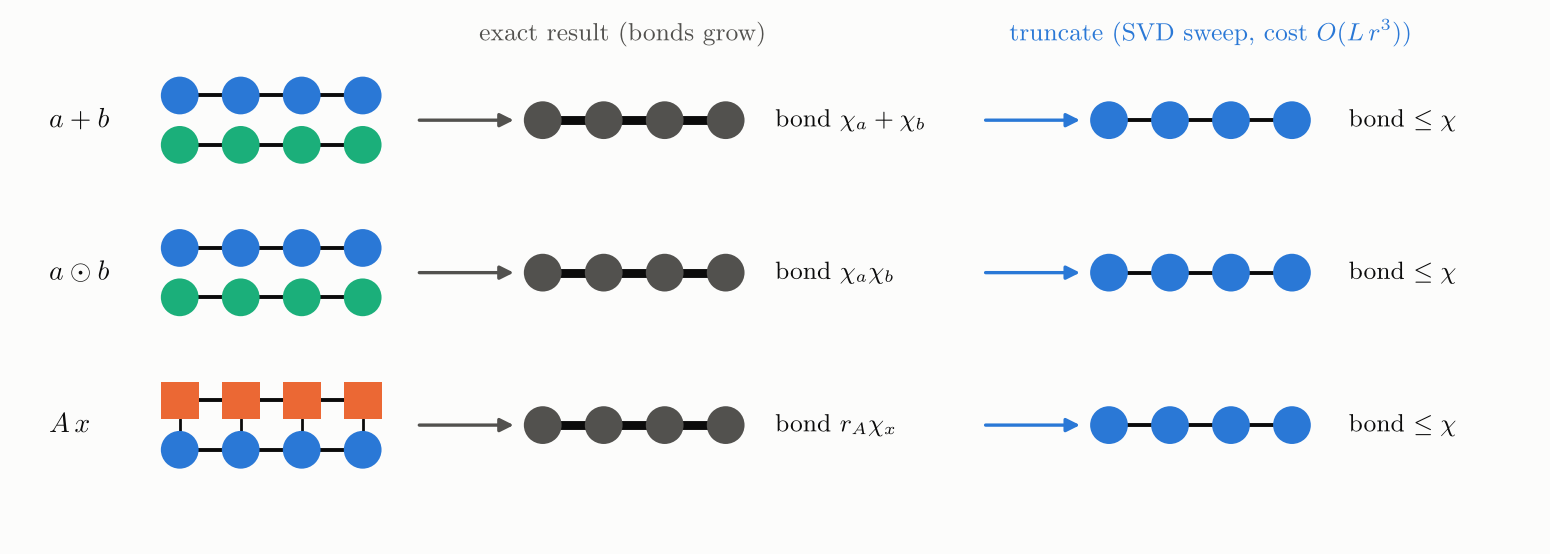

*Sums, pointwise products and operator applications enlarge the bonds; an SVD sweep truncates them back to at most $\chi$.*

| operation | CFD use | bond dimension before truncation | cost of truncation |
|---|---|---|---|
| $a+b$ | adding source terms, time update | $\chi_a+\chi_b$ | $O(L(\chi_a+\chi_b)^3)$ |
| $a\odot b$ (pointwise product) | convection $u\,\partial_x u$, masking $m\odot u$ | $\chi_a\chi_b$ | $O(L(\chi_a\chi_b)^3)$ |
| $A\,x$ (operator application) | gradients, divergence, diffusion | $r_A\chi_x$ | $O(L(r_A\chi_x)^3)$ |

A convective term $u\,\partial_x u$ reaches up to $\chi\cdot 3\chi$ before truncation (in the example below, $7\times5=35$), and the mask multiplies the rank of whatever it touches by $\chi_m$. **Truncation after every operation is unavoidable, and together with the pressure solve (§6) it is the main cost of a time step.** It is also the second source of compression error: each truncation discards a tail of relative size $\varepsilon$, or whatever the cap $\chi$ forces.

chi(u) = 7, chi(mask) = 62, chi(d_x u) = 5
$u\odot m$ (masking)                    : max bond  434 exact ->  64 truncated, error 1.7e-12
$u\odot\partial_x u$ (convection)       : max bond   35 exact ->  18 truncated, error 2.3e-12


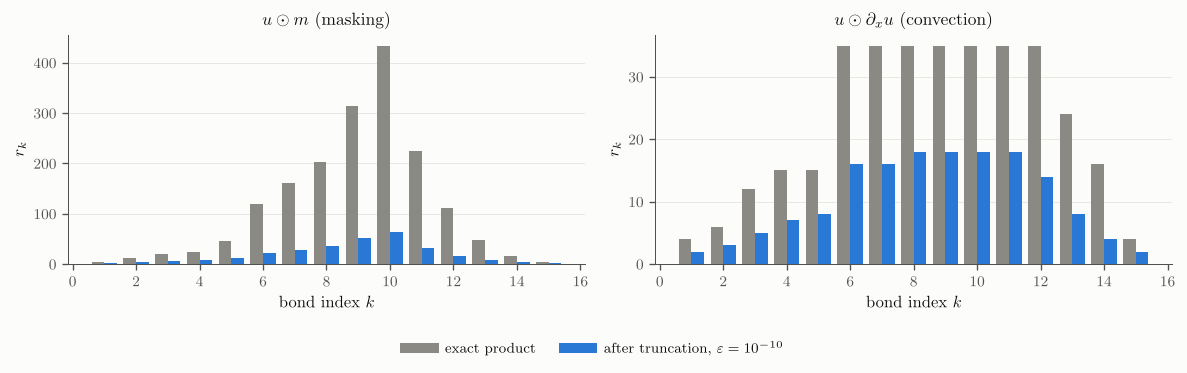

In [13]:
Q = 8
ops8 = CentralOps(Q)
X, Y = mesh(Q)
m = C.grid_to_mps(
    (1 - es.cylinder(torch.tensor(X), torch.tensor(Y), 0.5, 0.5, 0.15)).numpy(), Q, 1e-10
)  # cylinder mask
u = C.grid_to_mps(
    1 + 0.3 * np.sin(2 * np.pi * X) * np.cos(4 * np.pi * Y) + 0.1 * np.sin(6 * np.pi * Y), Q, 1e-10
)
dux = ops8.Dx.apply(u)
rows = [
    (r"$u\odot m$ (masking)", raw_product(u, m)),
    (r"$u\odot\partial_x u$ (convection)", raw_product(u, dux)),
]
print(
    f"chi(u) = {int(u.max_rank)}, chi(mask) = {int(m.max_rank)}, chi(d_x u) = {int(dux.max_rank)}"
)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.0))
for a, (lab, raw) in zip(ax, rows):
    trunc = raw.compress(accuracy=1e-10)
    k = np.arange(1, len(raw))
    a.bar(k - 0.2, ranks(raw)[1:-1], width=0.4, color=MUTED)
    a.bar(k + 0.2, ranks(trunc)[1:-1], width=0.4, color=BLUE)
    a.set_title(lab)
    a.set_xlabel(r"bond index $k$")
    a.set_ylabel(r"$r_k$")
    a.grid(axis="x", visible=False)
    print(
        f"{lab:40s}: max bond {int(raw.max_rank):4d} exact -> {int(trunc.max_rank):3d} truncated, "
        f"error {rel(trunc.contract(), raw.contract()):.1e}"
    )
fig.legend(
    handles=[
        Line2D([], [], color=MUTED, lw=6, label=r"exact product"),
        Line2D([], [], color=BLUE, lw=6, label=r"after truncation, $\varepsilon=10^{-10}$"),
    ],
    loc="lower center",
    ncol=2,
    bbox_to_anchor=(0.5, -0.04),
)
fig.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

Masking multiplies the rank of the velocity by that of the mask; truncation brings it back down, but never below what the mask itself needs. The geometry therefore sets a floor under the cost of every masked field.

## 6. The pressure-Poisson solve

*Pipeline stage: MPS subroutines, once per time step: the usual bottleneck of a standard incompressible solver too.*

The projection step solves $\nabla^2\phi=\nabla\!\cdot\mathbf u^*$ **entirely in compressed form**. Where a standard code would use CG, BiCGStab or algebraic multigrid on the assembled sparse matrix, here $\phi$ is itself an MPS and the solver (alternating minimal energy, AMEn, `tt.linsys_amen`) sweeps along the chain like a block Gauss–Seidel or line-relaxation method: at each pair of neighbouring cores it solves a **small dense local system** for those cores with the rest of the chain held fixed.

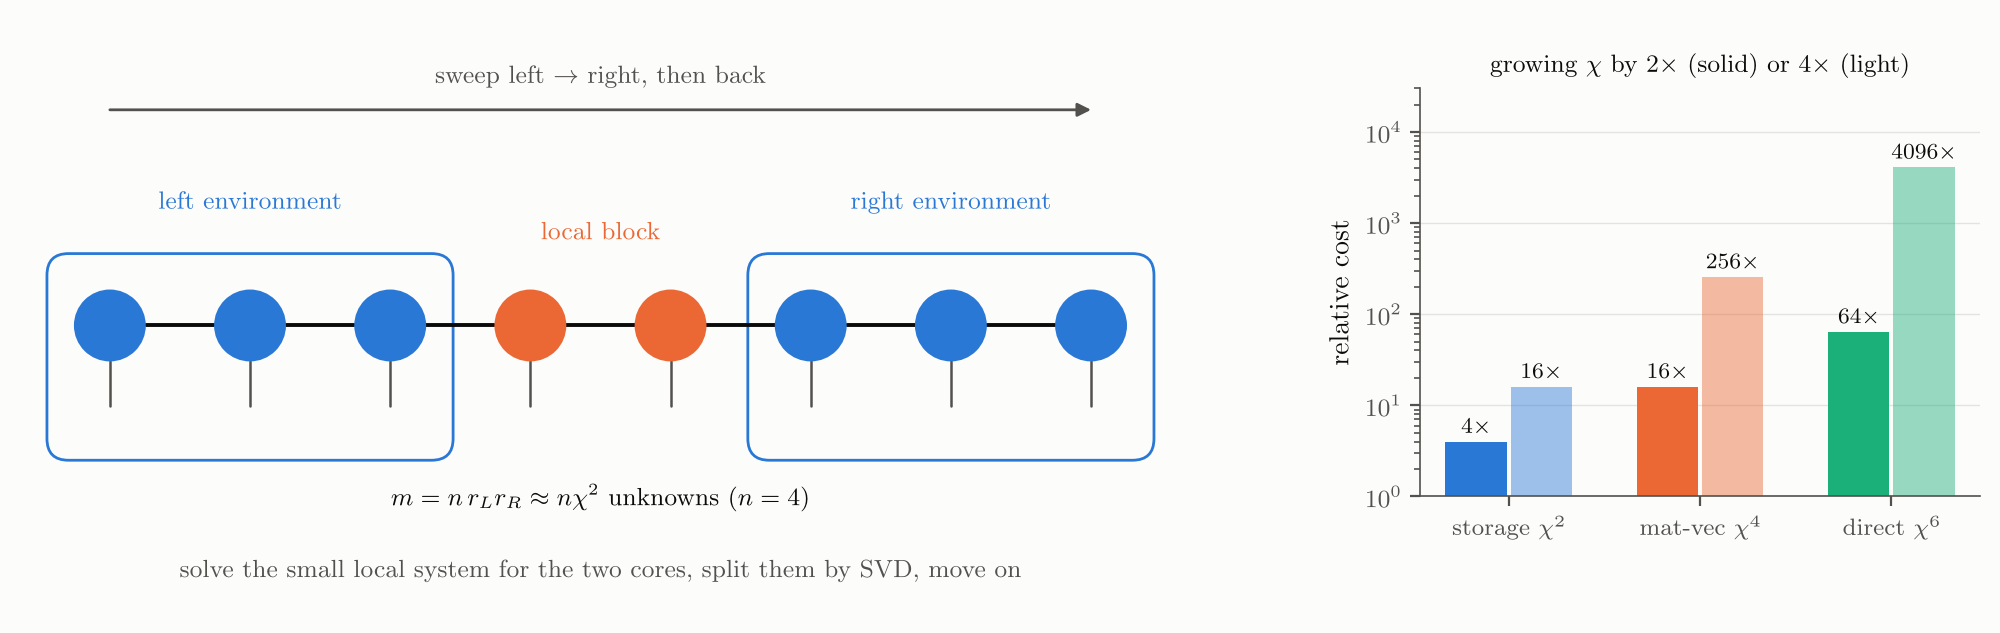

*Left: one step of a sweep. The cores to the left and right are contracted into fixed blocks ("environments"); the two highlighted cores are solved for together. Right: how the work grows when $\chi$ is doubled or quadrupled.*

The local system has $m \approx 4\chi^2$ unknowns, so:

| quantity | scaling | ×2 in $\chi$ | ×4 in $\chi$ |
|---|---|---|---|
| field storage | $O(L\chi^2)$ | 4× | 16× |
| local mat-vec, per inner iteration | $O(\chi^4)$ | 16× | 256× |
| local direct solve | $O(\chi^6)$ | 64× | 4096× |

In the production 2048² bundle run at $\chi = 80$, the local solve ran out of memory: the limit was the local systems and their factorisation workspaces, not the compressed fields.

Below: projections of a masked predictor on the periodic cylinder cell of §4.1. A uniform stream $U=1$ is masked by the cylinder, the momentum predictor is taken, and the resulting divergence is projected out. Only the rank cap on $\phi$ changes, as one would compare linear-solver settings in a standard code.

after predictor + mask: |div u*| dx/|u| = 4.38e-02



rank cap   4: solve failed (residual 1.5e+00 > 0.5)


rank cap   8: solve failed (residual 9.3e-01 > 0.5)


rank cap  16: Poisson residual 2.9e-01   |div u| dx/|u| = 1.3e-02   chi(phi) =  16    1.78s


rank cap  32: Poisson residual 1.5e-02   |div u| dx/|u| = 6.3e-04   chi(phi) =  32    2.75s


rank cap  48: Poisson residual 1.3e-02   |div u| dx/|u| = 5.3e-04   chi(phi) =  33    3.06s


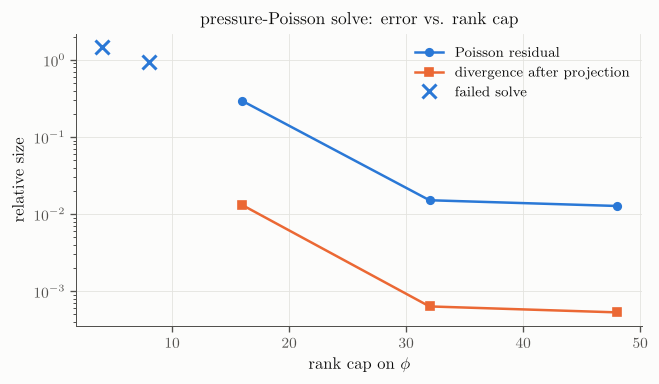

In [14]:
Q = 7
ops = CentralOps(Q)
X, Y = mesh(Q)
dx = ops.dx
msk = C.grid_to_mps(
    (1 - es.cylinder(torch.tensor(X), torch.tensor(Y), 0.5, 0.5, 0.15)).numpy(), Q
)  # D = 0.3
ux, uy = msk * 1.0, msk * 0.0  # uniform stream U = 1, zero inside the solid
dt, nu = 0.2 * dx, 2e-3  # convective CFL 0.2, Re = U D / nu = 150


def div_norm(a, b):  # dimensionless divergence |div u| dx / |u|
    return float(ops.divergence(a, b).norm) * dx / float(a.norm)


us, vs = C.predict_velocity(ux, uy, ops, dt, nu, msk, eps=1e-10, max_bd=32)
print(f"after predictor + mask: |div u*| dx/|u| = {div_norm(us, vs):.2e}\n")
ok, failed = [], []
for rank in [4, 8, 16, 32, 48]:
    t0 = time.time()
    out, bad = try_project(us, vs, ops, dt, rank)
    if out is None:
        failed.append((rank, bad))
        print(f"rank cap {rank:3d}: solve failed (residual {bad:.1e} > 0.5)")
        continue
    nx, ny, p, phi = out
    ok.append(
        (
            rank,
            C.project_divergence_free.last_residual,
            div_norm(nx, ny),
            int(phi.max_rank),
            time.time() - t0,
        )
    )
    print(
        f"rank cap {rank:3d}: Poisson residual {ok[-1][1]:.1e}   |div u| dx/|u| = {ok[-1][2]:.1e}   "
        f"chi(phi) = {ok[-1][3]:3d}   {ok[-1][4]:5.2f}s"
    )

fig, ax = plt.subplots(figsize=(5.6, 3.3))
rk_, res_, dv_, _, _ = zip(*ok)
ax.semilogy(rk_, res_, "o-", color=BLUE, label=r"Poisson residual")
ax.semilogy(rk_, dv_, "s-", color=ORANGE, label=r"divergence after projection")
if failed:
    ax.semilogy(
        [f[0] for f in failed],
        [f[1] for f in failed],
        "x",
        color=BLUE,
        ms=8,
        mew=1.8,
        label=r"failed solve",
    )
ax.set_xlabel(r"rank cap on $\phi$")
ax.set_ylabel(r"relative size")
ax.legend()
ax.set_title(r"pressure-Poisson solve: error vs. rank cap")
fig.tight_layout()
plt.show()

Below a rank cap of 16 the solve fails. Raising the cap from 16 to 32 cuts the residual twentyfold and the remaining divergence to about $6\times10^{-4}$; above 32 extra rank no longer helps: at a cap of 48 the solver uses only rank 33, so the remaining $\sim10^{-2}$ is set by other settings such as the number of sweeps. Choosing the rank cap is the same decision as choosing a linear-solver tolerance in a standard code. The wall times grow only modestly with the cap: on a $128^2$ mesh they are dominated by fixed overhead, and the $\chi^4$–$\chi^6$ growth of the table above appears only at production sizes.

## 7. Time steps of the projection method

*Pipeline stage: MPS subroutines: the full time-loop body, assembled from §3–§6.*

`chorin_projection.projection_step` implements a rotational incremental pressure-correction scheme, the fractional-step family used in standard incompressible solvers:

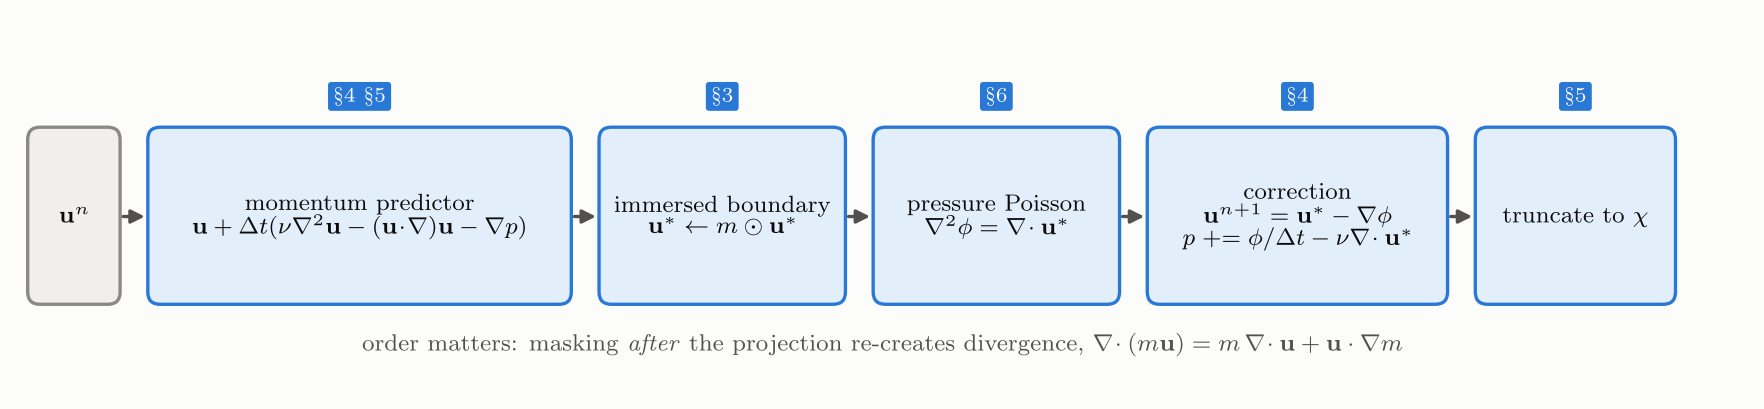

```
u*  = u + dt·( −(u·∇)u + ν∇²u − ∇p )          # momentum predictor: §4 operators, §5 products, then truncation
u*  = m ⊙ u*                                    # immersed boundary, BEFORE the projection: §3
solve  ∇²φ = ∇·u*                               # pressure Poisson: §6
u   = u* − ∇φ ;   p ← p + φ/dt − ν∇·u*          # velocity and pressure correction: §4, then truncation
```

Masking must come **before** the projection: masking afterwards re-creates divergence, $\nabla\!\cdot(m\mathbf u)=m\,\nabla\!\cdot\mathbf u+\mathbf u\cdot\nabla m$.

Below: three steps on the periodic cylinder cell, starting impulsively from a uniform stream at $Re = UD/\nu = 150$, with $\chi \le 32$. These steps show the start-up transient, not a developed wake.

 step   |div u| dx/|u|   Poisson residual   chi(u)   chi(p)   time


    1     6.35e-04         1.5e-02          32       32     3.25s


    2     8.15e-04         4.8e-02          32       32    14.14s


    3     7.62e-04         3.1e-02          32       32    13.45s


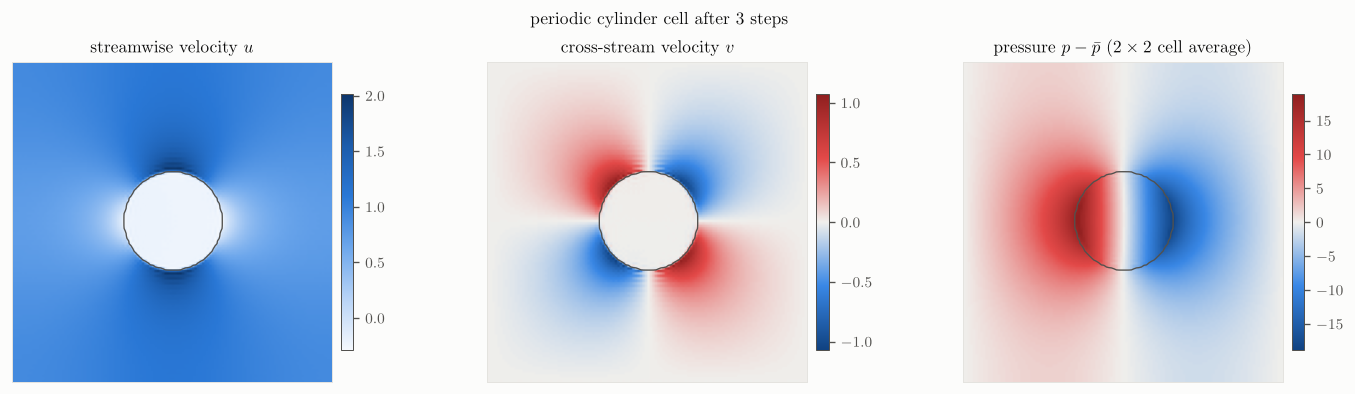

In [15]:
chi, nsteps = 32, 3
u_, v_, p_, guess = ux, uy, None, None
print(" step   |div u| dx/|u|   Poisson residual   chi(u)   chi(p)   time")
for n in range(nsteps):
    t0 = time.time()
    with contextlib.redirect_stdout(io.StringIO()):
        u_, v_, p_, guess = C.projection_step(
            u_, v_, ops, dt, nu, msk, eps=1e-10, max_bd=chi, opt_iter=8, guess=guess, pressure=p_
        )
    print(
        f"  {n + 1:3d}     {div_norm(u_, v_):.2e}         {C.project_divergence_free.last_residual:.1e}         {int(u_.max_rank):3d}"
        f"      {int(p_.max_rank):3d}    {time.time() - t0:5.2f}s"
    )

U_, V_, P_, Mk = (C.mps_to_grid(f, Q) for f in (u_, v_, p_, msk))
P_ = P_ - P_.mean()  # periodic pressure is defined up to a constant
P_avg = 0.25 * (P_ + np.roll(P_, 1, 0) + np.roll(P_, 1, 1) + np.roll(np.roll(P_, 1, 0), 1, 1))
xs_ = np.linspace(0, 1, 2**Q)
fig, ax = plt.subplots(1, 3, figsize=(12, 3.3))
panels = [
    (U_, r"streamwise velocity $u$", SEQ, False),
    (V_, r"cross-stream velocity $v$", DIV, True),
    (P_avg, r"pressure $p-\bar p$ ($2\times2$ cell average)", DIV, True),
]
for a, (fld, ttl, cmap, sym) in zip(ax, panels):
    lim = np.abs(fld).max()
    im = a.imshow(
        fld.T,
        origin="lower",
        cmap=cmap,
        extent=[0, 1, 0, 1],
        **({"vmin": -lim, "vmax": lim} if sym else {}),
    )
    a.contour(xs_, xs_, Mk.T, levels=[0.5], colors=INK2, linewidths=0.8)
    field_axes(a, ttl)
    fig.colorbar(im, ax=a, shrink=0.8, pad=0.02)
fig.suptitle(rf"periodic cylinder cell after {nsteps} steps", fontsize=10.5)
fig.tight_layout()
plt.show()

* **The cap is binding**: $\chi(u)$ and $\chi(p)$ sit at 32 at every step, so compression error is present in these fields.
* Step 1 is faster because there is no pressure yet; from step 2 the predictor also applies the pressure gradient, which adds operator applications and truncations at the $\chi$ cap.
* The pressure is shown averaged over $2\times2$ cells, which removes the odd–even mode of the collocated central-difference Laplacian; that mode has no effect on the velocity.
* **Monitors**, the equivalents of residual plots in a standard code: the continuity residual $|\nabla\!\cdot\mathbf u|\,\Delta x/|\mathbf u|$ (O(1) means the projection failed), the Poisson residual (≥ 0.5 is treated as a solver failure), and $\chi$ (whether the cap is binding).
* On a $128^2$ mesh an FFT or multigrid pressure solve takes milliseconds. The compressed solver pays off only on meshes large enough that a dense field is the bottleneck, and only if $\chi$ stays moderate there.

## 8. Post-processing a real result: error vs. $\chi$

*Pipeline stage: post-processing.*

`../data/archive/q11_q11_t2500_bd60_rk4.npz` holds output from the $2048^2$, $\chi=60$ bundle run, stored as $1024^2$ arrays. Re-compressing these fields at different $\chi$ shows **how much each quantity costs to represent**, the MPS analogue of asking how fine a mesh a quantity needs. The plots are cropped to the bundle and its near wake; the compression acts on the full field.

The arrays are stored in float16, which adds about $2$–$3\times10^{-4}$ relative rounding noise; the error curves flatten there. The faint rectangular, mesh-aligned patches in the vorticity are most likely truncation artefacts of the $\chi=60$ run itself: a derivative makes small compression errors visible.

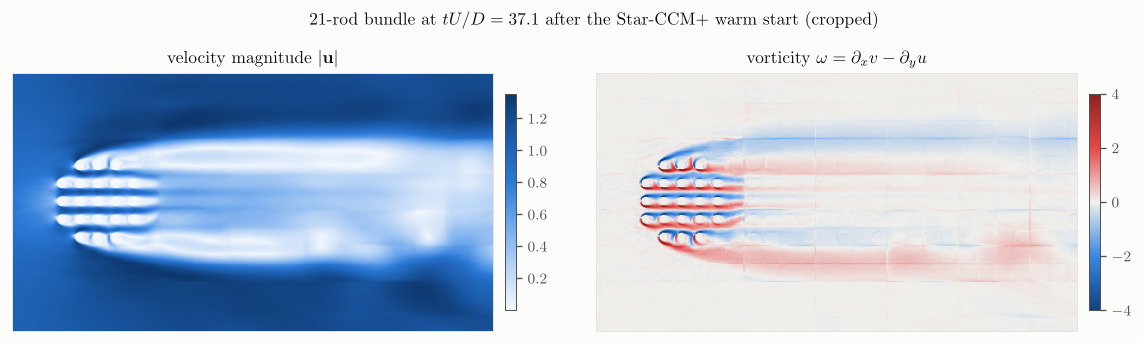

In [16]:
d = np.load("../data/archive/q11_q11_t2500_bd60_rk4.npz")
Q8 = 10
names = {
    "speed2": r"velocity magnitude $|\mathbf u|$",
    "vort2": r"vorticity $\omega=\partial_x v-\partial_y u$",
    "mask": r"mask $m$",
}
F = {k: torch.tensor(d[k].astype(np.float64)) for k in names}
ix, iy = np.where(F["mask"].numpy() < 0.5)
sx = slice(max(ix.min() - 40, 0), min(ix.max() + 320, 2**Q8))
sy = slice(max(iy.min() - 80, 0), min(iy.max() + 80, 2**Q8))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.0))
for a, k in zip(ax, ["speed2", "vort2"]):
    v = F[k].numpy()[sx, sy]
    im = (
        a.imshow(v.T, origin="lower", cmap=DIV, vmin=-4, vmax=4)
        if k == "vort2"
        else a.imshow(v.T, origin="lower", cmap=SEQ)
    )
    field_axes(a, names[k])
    fig.colorbar(im, ax=a, shrink=0.75, pad=0.02)
fig.suptitle(
    rf"21-rod bundle at $tU/D={d['t'][2]:.1f}$ after the Star-CCM+ warm start (cropped)",
    fontsize=10.5,
)
fig.tight_layout()
plt.show()

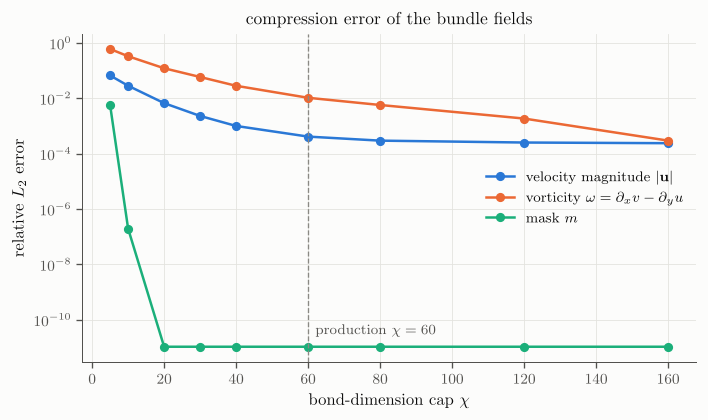

chi = 40: 33448 parameters per field, compression 31:1
   |u|        relative error 9.9e-04
   vorticity  relative error 2.8e-02
   mask       relative error 1.0e-11


In [17]:
chis8 = [5, 10, 20, 30, 40, 60, 80, 120, 160]
loss = {}
for k in names:
    full = enc2d(F[k], Q8, eps=1e-14)
    loss[k] = []
    for chi in chis8:
        c = full.compress(accuracy=1e-14, max_bd=chi)
        loss[k].append((c.num_params, rel(dec2d(c, Q8), F[k])))

col = {"speed2": BLUE, "vort2": ORANGE, "mask": AQUA}
fig, ax = plt.subplots(figsize=(6.0, 3.6))
for k in names:
    ax.semilogy(chis8, [e for _, e in loss[k]], "o-", color=col[k], label=names[k])
ax.axvline(60, color=MUTED, lw=0.8, ls="--")
ax.text(62, 3e-11, r"production $\chi=60$", fontsize=8.5, color=INK2)
ax.set_xlabel(r"bond-dimension cap $\chi$")
ax.set_ylabel(r"relative $L_2$ error")
ax.legend(loc="center right")
ax.set_title(r"compression error of the bundle fields")
fig.tight_layout()
plt.show()

i40 = chis8.index(40)
print(
    f"chi = 40: {loss['speed2'][i40][0]} parameters per field, compression {4**Q8 / loss['speed2'][i40][0]:.0f}:1"
)
for k, lab in zip(names, ["|u|", "vorticity", "mask"]):
    print(f"   {lab:10s} relative error {loss[k][i40][1]:.1e}")

* At $\chi = 40$ a $1024^2$ field takes 33 448 parameters, a 31:1 compression.
* At the same $\chi$, **vorticity, a derivative of the velocity, is about 30× less accurate than the velocity magnitude.** Derivatives magnify the fine scales that truncation removes.
* The bundle mask is exact from $\chi\approx20$. **The flow, not the geometry, sets the rank of this run.**
* **Choose $\chi$ from the quantity you report**, as one chooses the near-wall mesh from $y^+$ rather than from the free-stream velocity. Forces and Nusselt numbers depend on wall gradients and need more $\chi$ than the velocity field.

## 9. Reading results: the accuracy–cost trade-off

**MPS compression reduces cost in exchange for error.** It does not deliver the same answer more cheaply; it delivers a slightly different answer more cheaply, and $\chi$ sets how much of each. Engineers make this trade routinely:

| familiar choice | what is saved | what is paid | MPS counterpart |
|---|---|---|---|
| coarser mesh | cells, run time | discretisation error | smaller $\chi$ |
| looser solver tolerance | iterations | residual error | fewer sweeps, smaller rank cap on $\phi$ |
| reduced-order model (POD, ROM) | degrees of freedom | modal truncation error | truncation after every operation |

The new element is the middle term of the **error budget**:

$$
\underbrace{e_{\text{total}}}_{\text{vs. reference}} \;\approx\; \underbrace{e_{\text{disc}}(h,\,\Delta t)}_{\text{mesh, stencil, time step}} \;+\; \underbrace{e_{\text{repr}}(\chi,\varepsilon)}_{\text{compression (new)}} \;+\; \underbrace{e_{\text{solve}}(\text{sweeps},\,\chi_\phi)}_{\text{linear-solver tolerance}}
$$

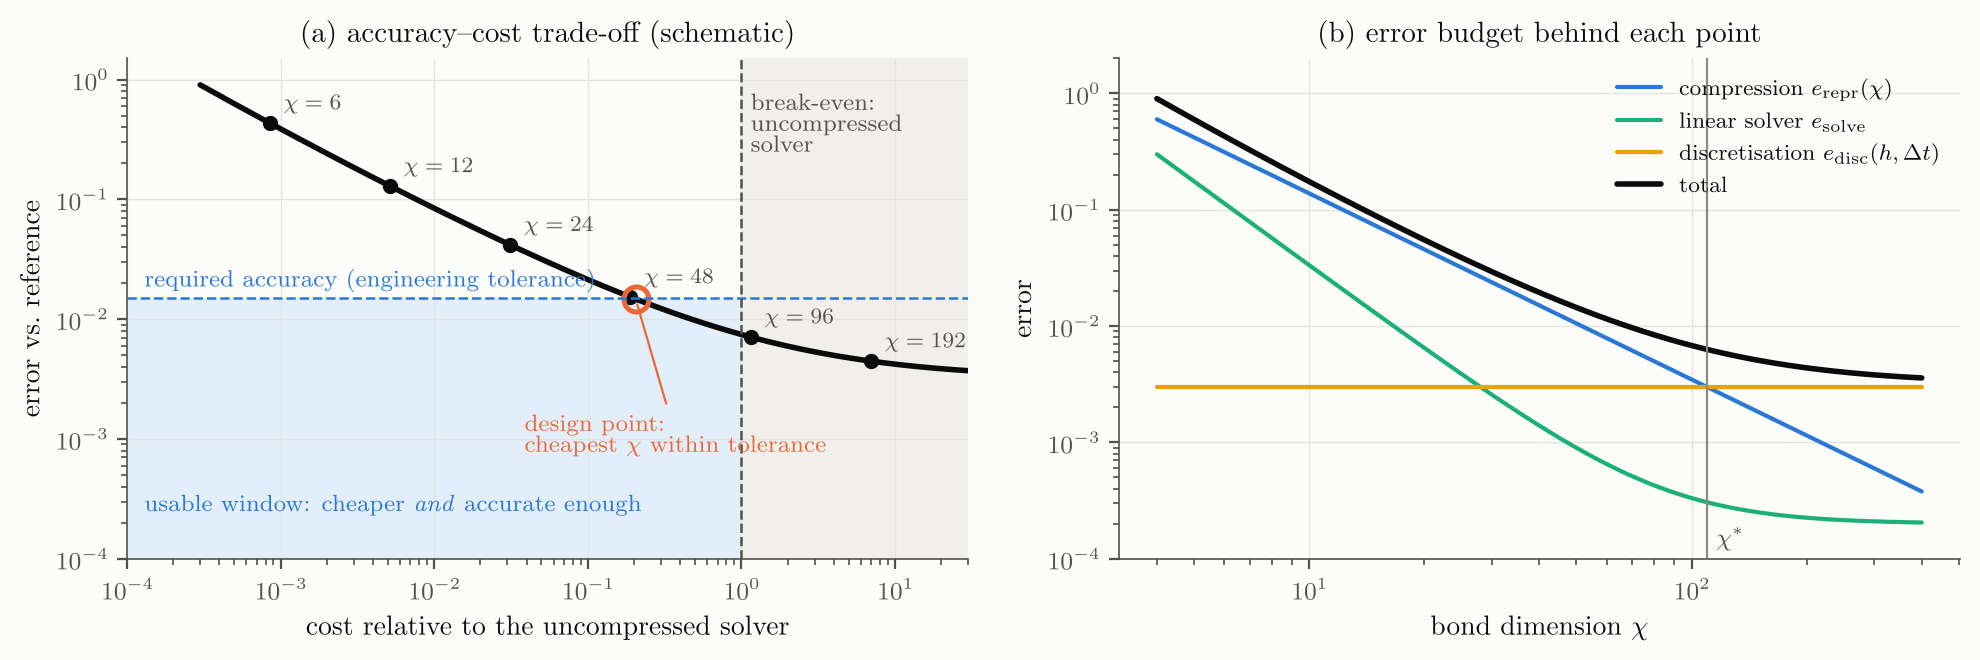

*Schematic. (a) Each $\chi$ is one operating point with a cost and an error. Small $\chi$ is cheap and inaccurate; large $\chi$ is accurate but eventually costs more than the uncompressed solver (break-even). The **design point** is the cheapest $\chi$ that meets the required accuracy. (b) Behind each point is an error budget: raising $\chi$ shrinks the compression error until it falls below the discretisation error at $\chi^\ast$; beyond that, extra $\chi$ buys little, as refining a mesh beyond grid convergence does.*

**How the cost side scales** ($L$ cores, $S$ sweeps, $k$ inner iterations, $r_A$ operator bond dimension):

| part of the calculation | storage | work per time step |
|---|---|---|
| fields ($u$, $v$, $p$, mask) | $O(L\chi^2)$ | – |
| pointwise products + truncation | – | $O(L\chi^6)$ |
| operator applications + truncation | – | $O(L\,r_A^3\chi^3)$ |
| pressure-Poisson local solves | $O(\chi^4)$ workspace | $O(SLk\chi^4)$ iterative, $O(SL\chi^6)$ direct |
| probes / full field export | – | $O(\#\text{points}\cdot L\chi^2)$ / $O(N)$ |

Memory grows like $\chi^2$, but the products and the pressure solve grow like $\chi^4$–$\chi^6$. **The memory saving is much larger than the run-time saving, and the run-time saving can turn negative** if the accuracy target forces a large $\chi$.

The cell below finds, for the §8 bundle fields, the cheapest $\chi$ that meets a given tolerance and the memory saving it allows. **These are lower bounds on the error**: they measure how well a correct field can be stored at that $\chi$. Errors accumulated during a run are larger; in the bundle run, $\chi=40$ went unstable although it stores $|\mathbf u|$ to $10^{-3}$.

 tolerance |     velocity magnitude     |         vorticity         
           |   chi      memory saving  |   chi      memory saving
     1e-01 |     5             1279:1  |    30               51:1 
     3e-02 |    10              363:1  |    40               31:1 
     1e-02 |    20              105:1  |    80               10:1 
     3e-03 |    30               51:1  |   120                5:1 
     1e-03 |    40               31:1  |   160                3:1 


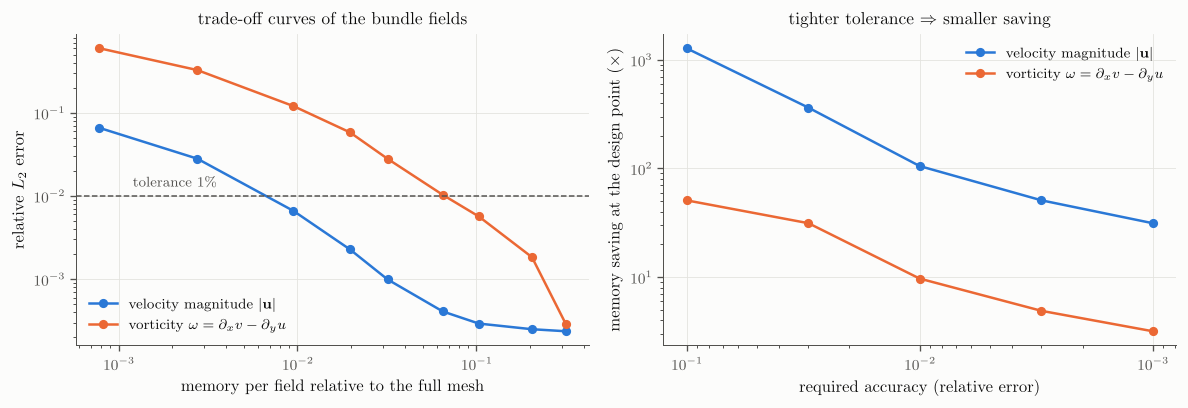

In [18]:
NQ = d["speed2"].size  # mesh values in the section-8 fields (1024^2)
tols = [1e-1, 3e-2, 1e-2, 3e-3, 1e-3]
print(f"{'tolerance':>10s} | {'velocity magnitude':^26s} | {'vorticity':^26s}")
print(f"{'':>10s} | {'chi':>5s} {'memory saving':>18s}  | {'chi':>5s} {'memory saving':>18s}")
design = {k: [] for k in ("speed2", "vort2")}
for tol in tols:
    row = []
    for k in ("speed2", "vort2"):
        hit = [(chi, p) for chi, (p, e) in zip(chis8, loss[k]) if e <= tol]
        if hit:
            chi_d, p_d = hit[0]
            design[k].append((tol, chi_d, NQ / p_d))
            row.append(f"{chi_d:5d} {NQ / p_d:16.0f}:1 ")
        else:
            design[k].append((tol, None, None))
            row.append(f"{'--':>5s} {'not reached':>18s} ")
    print(f"{tol:10.0e} | " + " | ".join(row))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for k, c in (("speed2", BLUE), ("vort2", ORANGE)):
    p, e = zip(*loss[k])
    ax[0].loglog([q / NQ for q in p], e, "o-", color=c, label=names[k])
    pts = [(t, x) for t, ch, x in design[k] if ch]
    ax[1].loglog([t for t, _ in pts], [x for _, x in pts], "o-", color=c, label=names[k])
ax[0].axhline(1e-2, color=INK2, ls="--", lw=0.9)
ax[0].text(1.2e-3, 1.3e-2, r"tolerance $1\%$", fontsize=8.5, color=INK2)
ax[0].set_xlabel(r"memory per field relative to the full mesh")
ax[0].set_ylabel(r"relative $L_2$ error")
ax[0].set_title(r"trade-off curves of the bundle fields")
ax[0].legend(loc="lower left")
ax[1].set_xlabel(r"required accuracy (relative error)")
ax[1].set_ylabel(r"memory saving at the design point ($\times$)")
ax[1].invert_xaxis()
ax[1].legend()
ax[1].set_title(r"tighter tolerance $\Rightarrow$ smaller saving")
fig.tight_layout()
plt.show()

**Rules of thumb for reading a result**

1. **State the tolerance first, then read off the saving.** The saving is the cheapest $\chi$ that meets *your* accuracy on *your* quantity; at a 1 % tolerance the same flow allows 105:1 for velocity but only 10:1 for vorticity.
2. **Do a $\chi$-sensitivity study as you would a mesh-sensitivity study, on the quantity you report.** Velocity converges at a lower $\chi$ than vorticity, wall gradients, forces or Nusselt numbers (§8). In the bundle run, $\chi=40$ was unstable, $\chi=60$ was stable and $\chi=80$ ran out of memory in the pressure solve, so the design point for the forces lies between 60 and the memory limit.
3. **Memory savings are not run-time savings.** In the project report's $1024^2$ bundle run (a separate run from the $2048^2$ one in §8), one MPS time step took 64 s on an RTX A6000 GPU, against 9 s for the uncompressed solver on 32 CPU threads. Break-even requires $\chi$ to stop growing under mesh refinement. §3 suggests this may happen once interfaces are resolved, but §8 shows that in the bundle run the flow, not the geometry, sets $\chi$.
4. **Compression is a property of the flow, not of the method.** Smooth fields on fine meshes compress well; under-resolved, mesh-misaligned interfaces and developed wakes need larger $\chi$ (§3, §8), which moves the design point towards break-even.
5. **Compare at matched accuracy**: time and peak memory to reach a target error in the engineering quantity, never compression ratio alone.